In [146]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib
import numpy as np
import scipy.optimize
import odrpack
import csv
import pandas as pd

plt.rcParams["figure.dpi"] = 150
plt.rcParams["text.usetex"] = True
plt.rcParams["font.size"] = 12


# matplotlib.rcParams['mathtext.fontset'] = 'stix'
# matplotlib.rcParams['font.family'] = 'Computer Modern'


plt.rcParams['font.family'] = 'serif' # or 'sans-serif' or 'monospace'
plt.rcParams['font.serif'] = 'cmr10'
plt.rcParams['font.sans-serif'] = 'cmss10'
plt.rcParams['font.monospace'] = 'cmtt10'
plt.rcParams["axes.formatter.use_mathtext"] = True # to fix the minus signs
%config InlineBackend.figure_format = 'retina'
plt.rcParams['axes.grid'] = True

In [147]:
brass_data = pd.read_csv('data/exp4_brass_1.csv')
copper_data = pd.read_csv('data/exp4_copper_1.csv')
aluminum_data = pd.read_csv('data/exp4_aluminum_1.csv')

In [148]:
rod_diameter = 12.80
rod_diameter_err = 0.05

T_bath = 6.143
T_bath_err = 0.042

length = np.array([205, 204.5, 204.8])
length_err = np.array([5, 5, 5])

densities = np.array([2.70, 8.5, 8.96]) / 1000  #g per mm^3
densities_err = np.array([0.1, 0.1, 0.1]) / 1000

heat_capacities = np.array([0.897, 0.380, 0.385]) #J per g per C
heat_capacities_err = np.array([0.010, 0.010, 0.010])

In [149]:
start_idx = np.argmin(np.abs(copper_data['Data Set 1:Time(s)'] - 40))
stop_idx = len(copper_data['Data Set 1:Time(s)']) - 1

times = np.array([
    aluminum_data['Data Set 1:Time(s)'].to_numpy(),
    brass_data['Data Set 1:Time(s)'].to_numpy(),
    copper_data['Data Set 1:Time(s)'].to_numpy()[start_idx:stop_idx] - copper_data['Data Set 1:Time(s)'].to_numpy()[start_idx]], dtype=pd.Series)


temps = np.array([
    aluminum_data['Data Set 1:Temperature(°C)'].to_numpy(),
    brass_data['Data Set 1:Temperature(°C)'].to_numpy(),
    copper_data['Data Set 1:Temperature(°C)'].to_numpy()[start_idx:stop_idx]], dtype=pd.Series)


temp_err = 0.03 #Precision of instrument


In [150]:
def fit_curve(t, T0, gamma):
    return (4*(T0-T_bath) / np.pi) * np.exp(-gamma * t / 2) + T_bath


gamma = np.ones(3)
T0 = np.ones(3)
gamma_err = np.ones(3)
T0_err = np.ones(3)

slice_indices = [200, 300, 100]

for i in range(3):
    popt, pcov = scipy.optimize.curve_fit(fit_curve, times[i][slice_indices[i]:], temps[i][slice_indices[i]:], maxfev=10000, bounds=([10, 0.001], [50, 0.05]), p0=[30, 0.005])

    gamma[i] = popt[1]
    T0[i] = popt[0]
    gamma_err[i] = np.sqrt(pcov[1][1])
    T0_err[i] = np.sqrt(pcov[0][0])


conductivity = 1000 * heat_capacities * densities * gamma * length**2 / np.pi**2  #W per m per C

conductivity_err = conductivity * np.sqrt((heat_capacities_err / heat_capacities)**2 + (densities_err / densities)**2 + (gamma_err / gamma)**2 + (2 * length_err / length)**2)

relative_conductivities = conductivity / conductivity[0]

relative_conductivities_err = np.sqrt((conductivity_err / conductivity[0])**2 + (conductivity_err[0] * conductivity / conductivity[0]**2)**2)
relative_conductivities_err[0] = 0

print(conductivity)

[17.09633906 17.84351334 37.36593934]


Aluminum 208.1878251102811
Brass 5.809946010981763
Copper 4.989235457489137


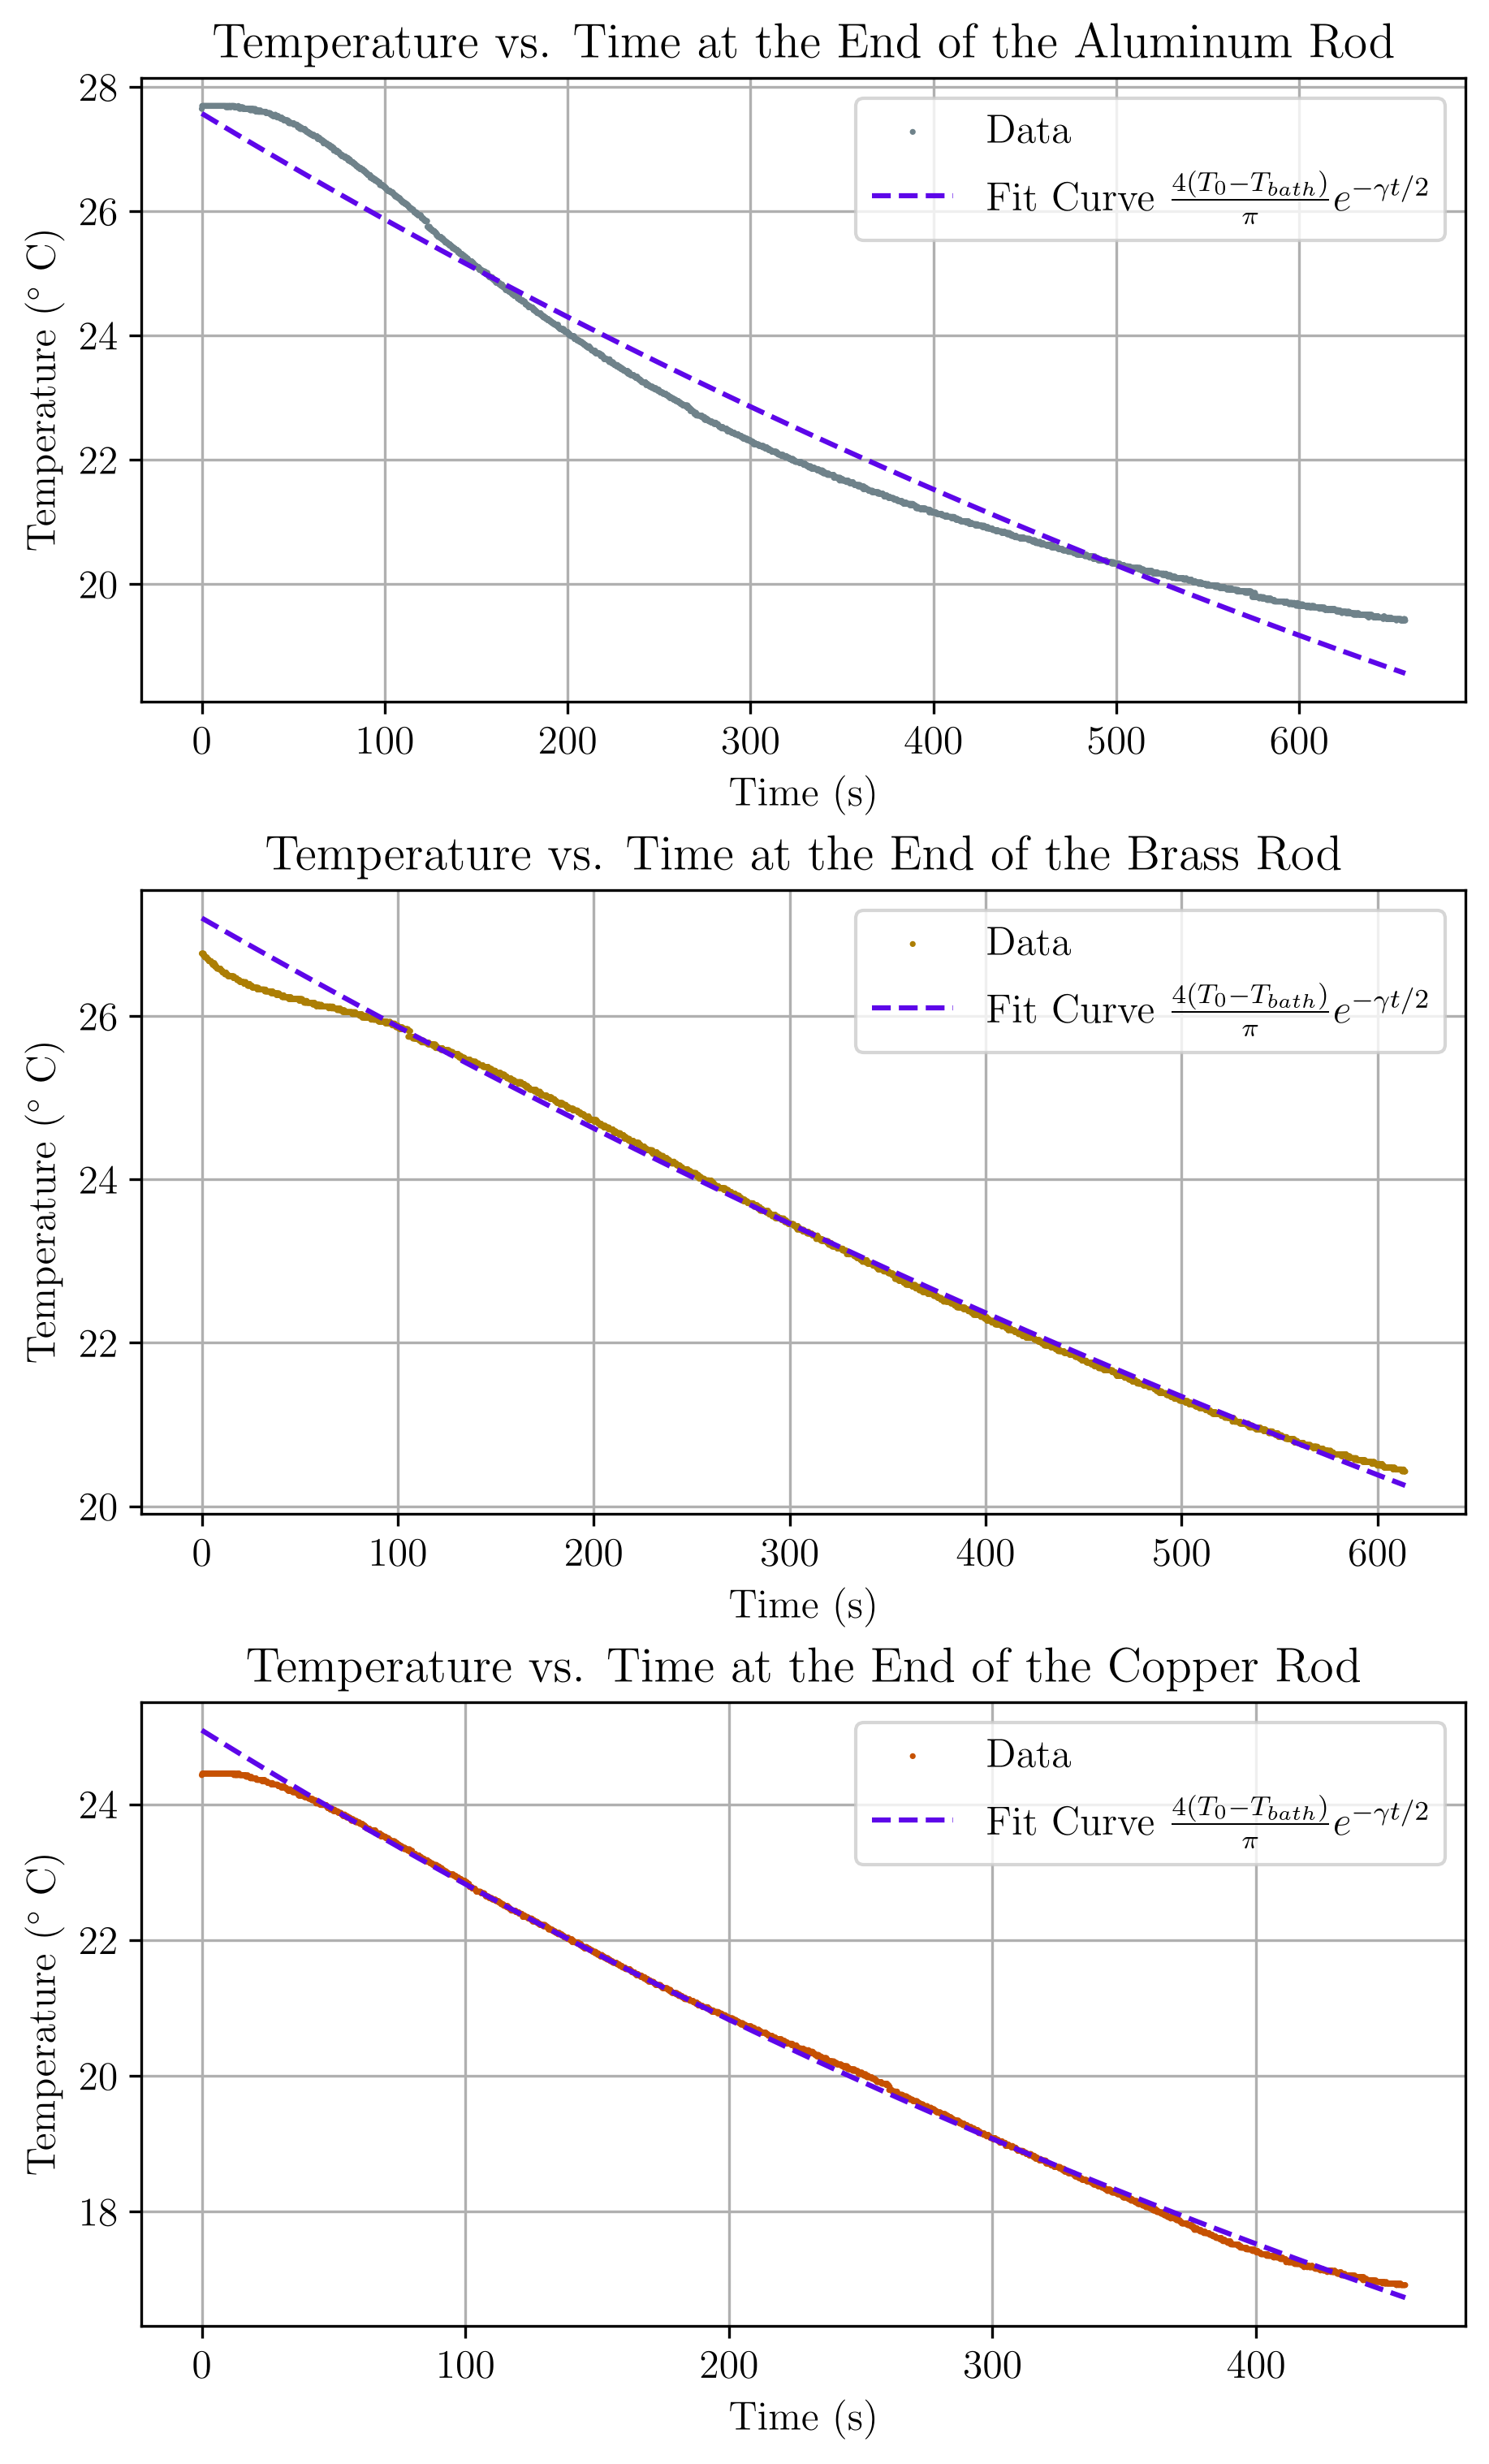

In [151]:
fig, axs = plt.subplots(3, figsize=(6, 10), layout='constrained')

metals = ['Aluminum', 'Brass', 'Copper']
colors = ['xkcd:steel grey', 'xkcd:mustard brown', 'xkcd:dark orange']

for i, ax in enumerate(axs):
    ax.scatter(times[i], temps[i], edgecolors='none', s = 3, color = colors[i], label = 'Data', zorder=10)

    x_vals = np.linspace(0, max(times[i]), 100)


    ax.plot(x_vals, fit_curve(x_vals, T0[i], gamma[i]), linestyle = 'dashed', color='xkcd:blue violet', zorder = 11,
             label = r"Fit Curve $\frac{4(T_0-T_{bath})}{\pi} e^{-\gamma t / 2}$")


    ax.set_title(f"Temperature vs. Time at the End of the {metals[i]} Rod")
    ax.set_xlabel(r"Time (s)")
    ax.set_ylabel(r"Temperature ($^\circ$ C)")

    ax.legend()

    fig.savefig("plots/rods_temp_vs_time.png", dpi=400)

    chi2 = np.sum((temps[i][slice_indices[i]:] - fit_curve(times[i][slice_indices[i]:], T0[i], gamma[i]))**2 / temp_err**2)
    reduced_chi2 = chi2 / (len(temps[i][slice_indices[i]:])-2)

    print(metals[i], reduced_chi2)

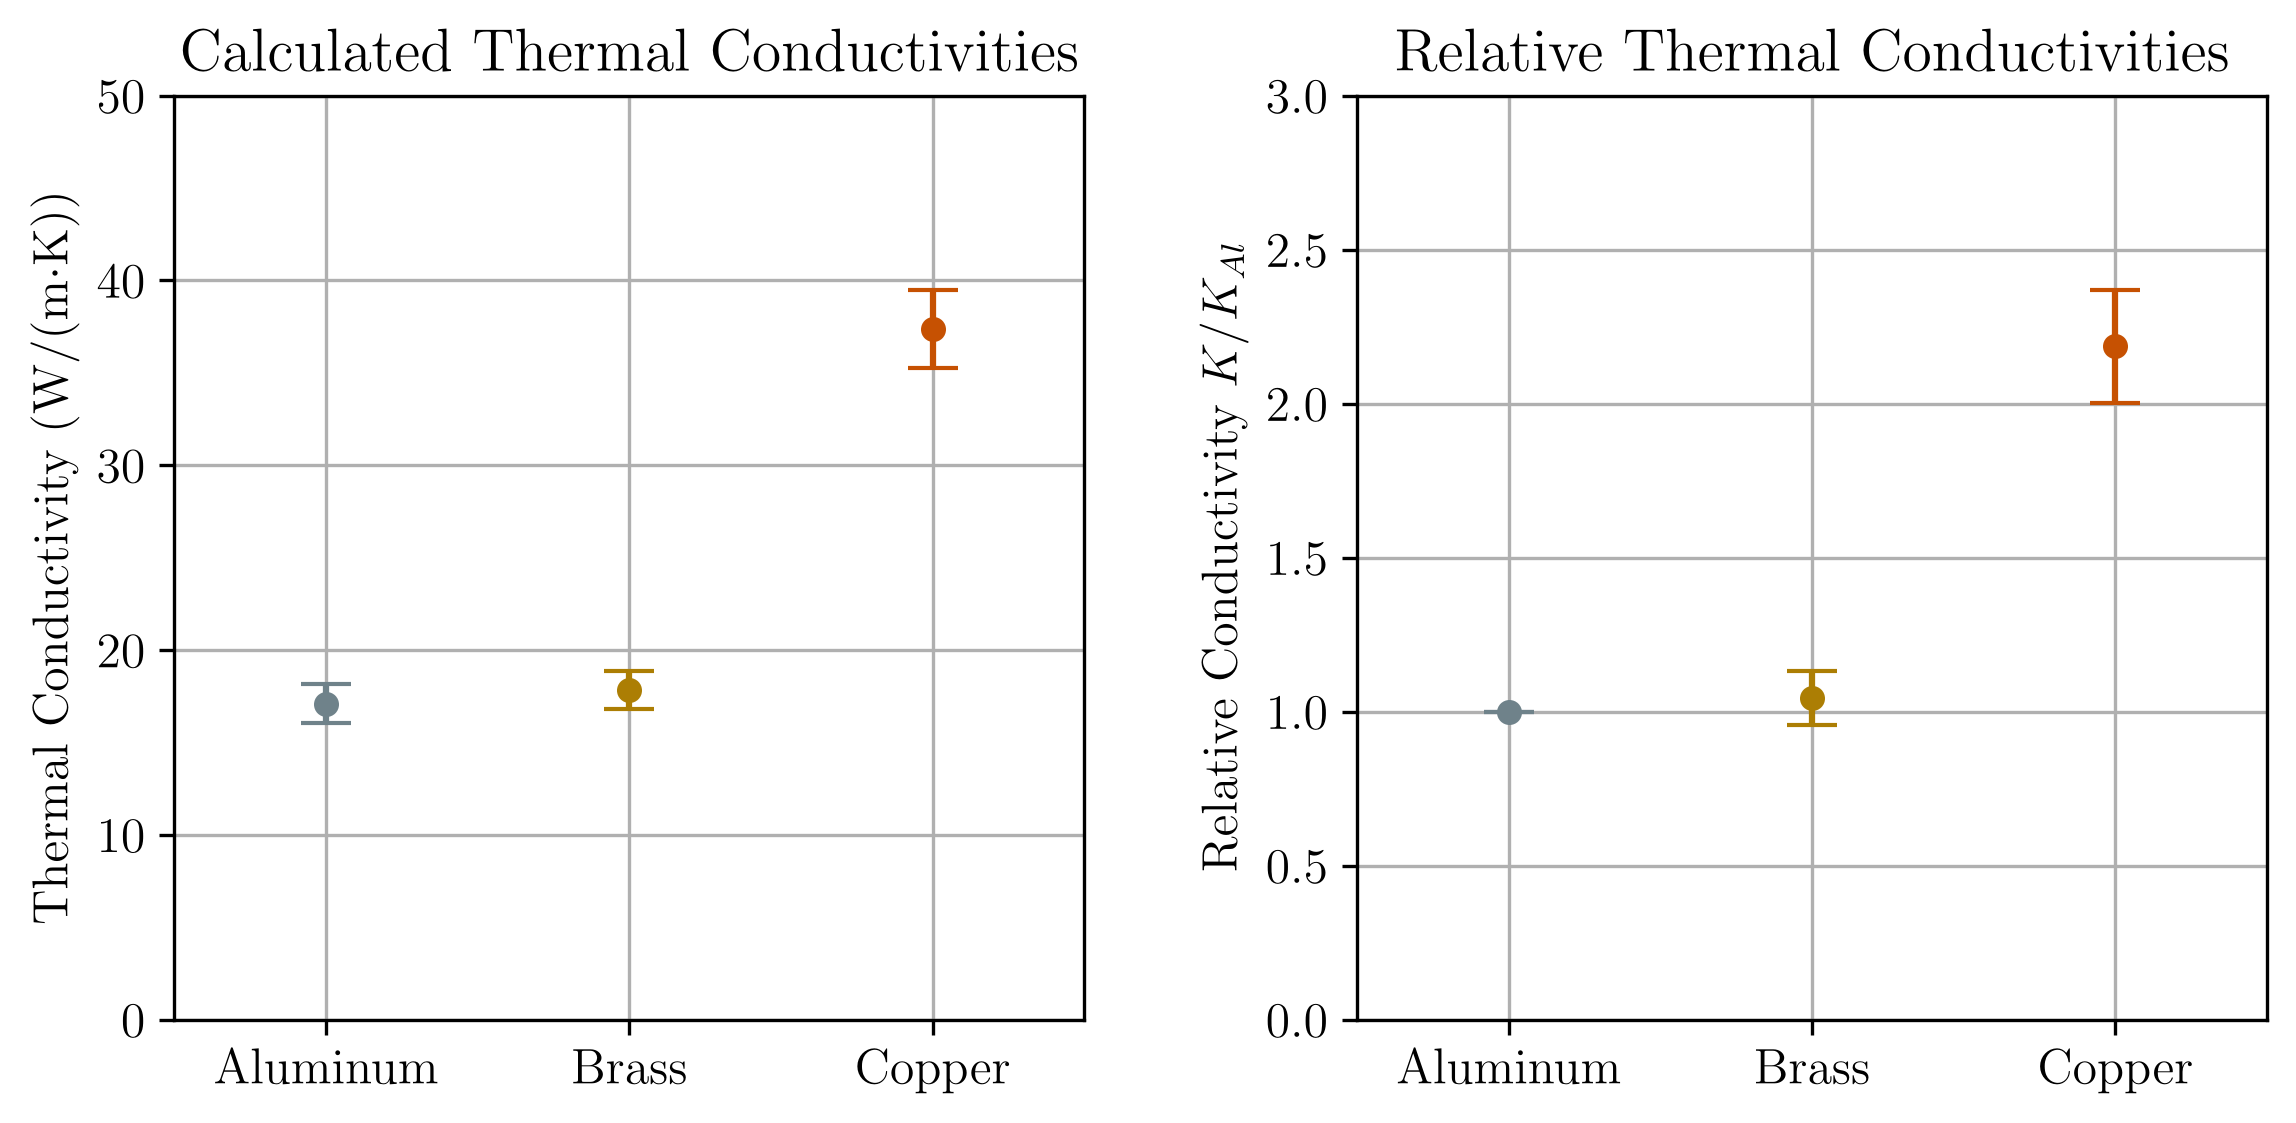

In [153]:
K_fig, K_axs = plt.subplots(1, 2, figsize=(9, 4))

K_fig.subplots_adjust(wspace = 0.3)

K_axs[0].set_xticks([1, 2, 3])
K_axs[0].set_xticklabels(metals)

for i in range(3):
    K_axs[0].errorbar(i+1, conductivity[i], conductivity_err[i], fmt = 'o', markersize = 5, capsize = 6, color = colors[i], zorder=10)

K_axs[0].set_title(rf"Calculated Thermal Conductivities")

K_axs[0].xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(1))
K_axs[0].set_xlim(0.5, 3.5)
K_axs[0].set_ylim(0, 50)
K_axs[0].set_ylabel(r"Thermal Conductivity (W/(m$\cdot$K))")




K_axs[1].set_xticks([1, 2, 3])
K_axs[1].set_xticklabels(metals)

for i in range(3):
    K_axs[1].errorbar(i+1, relative_conductivities[i], relative_conductivities_err[i], fmt = 'o', markersize = 5, capsize = 6, color = colors[i], zorder=10)

K_axs[1].set_title(rf"Relative Thermal Conductivities")

K_axs[1].xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(1))
K_axs[1].set_xlim(0.5, 3.5)
K_axs[1].set_ylim(0, 3)
K_axs[1].set_ylabel(r"Relative Conductivity $K / K_{Al}$")

K_fig.savefig("plots/rod_conductivities.png", dpi=400)
